# 🕵️ Falsification round 2: do the winners survive?

## 🧭 tl;dr

Notebook 54 destroyed the library's most exciting result. This one asks the harder question: **is anything here true?**

Four claims, chosen because each is the strongest survivor of its family:

| Claim | Source | Verdict |
| --- | --- | --- |
| **SPY 200-day trend gate** beats buy-and-hold on risk-adjusted return | notebook 52 | **Partly.** Alpha 3.40%/yr with **t = 2.13** over 33 years and drawdown −25% vs −55%, but it loses on Sharpe for 4 of 7 other assets, its 6-window grid has **p = 0.12**, and it beats buy-and-hold on return in only **3 of 32 years** |
| **ERC** has alpha against the equity market | notebook 50 | **No.** 3.73%/yr alpha (t = 2.88) against SPY collapses to **1.83% (t = 1.93)** once duration is a second regressor. The alpha was bond exposure |
| **Equal weight** has alpha | notebook 50 | **No.** 1.72% (t = 1.38) becomes **0.32% (t = 0.30)** with TLT in the regression |
| **Deflated Sharpe passes**, therefore something is real | notebook 54's method | **No.** A long-only sleeve passes the deflated Sharpe trivially, because beta is a real premium. The test only means something on **beta-adjusted** returns |

The conclusion of the whole project, stated plainly: **this library contains real risk-reduction technology and no demonstrable alpha.** Every apparent alpha is a beta — to equities, or to duration, or both.

<div style="border-left: 5px solid #2563EB; padding: 0.85em 1em; margin: 1em 0 1.4em; background: #EFF6FF; border-radius: 8px;"><strong>🧑‍🏫 Reader guide</strong><br>The most useful sentence in this notebook is "against <em>which</em> benchmark?". A single-market regression makes a bond-heavy portfolio look skilful; adding one regressor destroys the illusion. Read section 4 before the verdict.</div>

## ❄️ The claims under test, frozen

Chosen before running anything, because they are the four numbers the repository currently puts in front of a reader:

1. **Trend gate**: hold SPY when it is above its 200-day average, cash otherwise, decided daily on the prior close, 10 bps costs. Claimed result: 0.67 test-period Sharpe in notebook 52 and 0.35 in 2022–2025 against 0.08 for the credit filter.
2. **ERC**: equal risk contribution across ten ETFs, monthly, OAS-shrunk 252-day covariance. Claimed result: best-balanced risk contributions and a 0.65 test Sharpe.
3. **Equal weight**: ten ETFs, monthly, no estimation at all. Claimed result: 0.75 test Sharpe, beating every optimiser.
4. **Method claim**: a deflated Sharpe ratio above 0.95 means a result survives its own search.

## 📚 Why these tests

- [Harvey, Liu & Zhu (2016)](https://doi.org/10.1093/rfs/hhv059) — in a field with this many tried factors, t = 2.0 is not a discovery; their suggested bar is around t = 3.
- [Fama & French (1993)](https://doi.org/10.1016/0304-405X(93)90023-5) — a return has to be attributable to a priced factor before it can be called alpha.
- [White (2000)](https://doi.org/10.1111/1468-0262.00152) — the null for a grid is about the maximum, not the chosen cell.
- [Bailey & López de Prado (2014)](https://papers.ssrn.com/sol3/papers.cfm?abstract_id=2460551) — the deflated Sharpe ratio, and its dependence on the number of trials.
- [Daniel & Moskowitz (2016)](https://doi.org/10.1016/j.jfineco.2015.12.002) — timing strategies change their beta, so a constant-beta regression can understate or overstate what they earn.

In [1]:
from pathlib import Path
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    if (ROOT.parent / "src").exists():
        ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.backtest import split_time_series
from src.data import load_price_panel, make_demo_ohlcv
from src.factor_audit import (
    alpha_beta,
    annualized_sharpe,
    beta_adjusted_returns,
    bootstrap_pvalue,
    deflated_sharpe_ratio,
    stationary_block_bootstrap,
)
from src.macro_regimes import trend_gate_weights
from src.portfolio import (
    equal_risk_contribution_weights,
    equal_weight_weights,
    run_portfolio_backtest,
)
from src.research import metrics_for_period

plt.rcParams.update({
    "figure.figsize": (12, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})
pd.set_option("display.width", 150)

In [2]:
def load(tickers, start, end="2026-01-01"):
    try:
        return load_price_panel(tickers, start, end), "Yahoo Finance adjusted daily closes"
    except Exception as exc:
        dates = pd.bdate_range(start, end)
        demo = make_demo_ohlcv(periods=len(dates), seed=77, start=start)["close"]
        panel = pd.DataFrame({ticker: demo * (1.0 + 0.02 * i) for i, ticker in enumerate(tickers)}, index=demo.index)
        return panel, f"deterministic demo fallback ({type(exc).__name__})"


spy_long, spy_source = load(["SPY"], "1993-01-01")
multi_long, multi_source = load(["SPY", "TLT", "IEF"], "2003-01-01")
panel, panel_source = load(["SPY", "QQQ", "EFA", "EEM", "TLT", "IEF", "LQD", "HYG", "GLD", "DBC"], "2007-01-01")
assets, assets_source = load(["QQQ", "XLK", "IWM", "EFA", "EEM", "TLT", "GLD"], "2003-01-01")

print(f"SPY alone:  {spy_long.index.min().date()} to {spy_long.index.max().date()} ({len(spy_long):,} sessions) - {spy_source}")
print(f"SPY+TLT:    {multi_long.index.min().date()} to {multi_long.index.max().date()} ({len(multi_long):,} sessions)")
print(f"10-ETF:     {panel.index.min().date()} to {panel.index.max().date()} ({len(panel):,} sessions)")
print(f"7 assets:   {assets.index.min().date()} to {assets.index.max().date()} ({len(assets):,} sessions)")


def gate_weights(close, *, asset="SPY", window=200, defensive_assets=()):
    """Hold the asset above its average, else the defensive assets (or cash)."""
    prior = close[asset].shift(1)
    above = prior > prior.rolling(window, min_periods=window).mean()
    weights = pd.DataFrame(0.0, index=close.index, columns=close.columns)
    weights.loc[above.fillna(False), asset] = 1.0
    defensive = [column for column in defensive_assets if column in close.columns]
    if defensive:
        weights.loc[(~above).fillna(True), defensive] = 1.0 / len(defensive)
    weights.loc[above.isna(), :] = 0.0
    return weights


def book_metrics(book, close, benchmark, index=None, cost_bps=10.0):
    result = run_portfolio_backtest(close, book, transaction_cost_bps=cost_bps, benchmark_returns=benchmark)
    if index is None:
        return result, result.metrics
    return result, metrics_for_period(result, index)

SPY alone:  1993-01-29 to 2025-12-31 (8,288 sessions) - Yahoo Finance adjusted daily closes
SPY+TLT:    2003-01-02 to 2025-12-31 (5,787 sessions)
10-ETF:     2007-04-11 to 2025-12-31 (4,713 sessions)
7 assets:   2004-11-18 to 2025-12-31 (5,313 sessions)


## 1️⃣ The trend gate over 33 years

The gate is the simplest possible timing rule and the one that beat every macro filter in notebook 52. Testing it on SPY back to 1993 gives it the longest history in the library — and the most statistical power any claim here will get.

In [3]:
spy_benchmark = spy_long["SPY"].pct_change().fillna(0.0)
gate_book = gate_weights(spy_long)
buy_hold_book = pd.DataFrame(1.0, index=spy_long.index, columns=["SPY"])

gate_result, gate_metrics = book_metrics(gate_book, spy_long, spy_benchmark)
hold_result, hold_metrics = book_metrics(buy_hold_book, spy_long, spy_benchmark)

headline = pd.DataFrame({"trend gate (200d, cash defence)": gate_metrics, "SPY buy & hold": hold_metrics}).T
display(headline[["annualized_return", "annualized_volatility", "sharpe_ratio", "sortino_ratio", "max_drawdown", "calmar_ratio", "annualized_turnover"]].style.format({
    "annualized_return": "{:.2%}", "annualized_volatility": "{:.2%}", "sharpe_ratio": "{:.2f}",
    "sortino_ratio": "{:.2f}", "max_drawdown": "{:.2%}", "calmar_ratio": "{:.2f}", "annualized_turnover": "{:.1f}",
}))

years_beaten = 0
years_total = 0
for year in range(1994, 2026):
    index = spy_long.loc[str(year)].index
    if len(index) < 60:
        continue
    years_total += 1
    years_beaten += int(metrics_for_period(gate_result, index)["annualized_return"] > metrics_for_period(hold_result, index)["annualized_return"])
print(f"Years where the gate beat buy-and-hold on return: {years_beaten} of {years_total}")

,annualized_return,annualized_volatility,sharpe_ratio,sortino_ratio,max_drawdown,calmar_ratio,annualized_turnover
"trend gate (200d, cash defence)",7.91%,11.99%,0.70,0.97,-24.99%,0.32,6.5
SPY buy & hold,10.68%,18.63%,0.64,0.91,-55.19%,0.19,0.0


Years where the gate beat buy-and-hold on return: 3 of 32


In [4]:
decade_rows = []
for label, (start, end) in {"1993-1999": ("1993", "1999"), "2000-2009": ("2000", "2009"), "2010-2019": ("2010", "2019"), "2020-2025": ("2020", "2025")}.items():
    index = spy_long.loc[start:end].index
    gate_metrics = metrics_for_period(gate_result, index)
    hold_metrics = metrics_for_period(hold_result, index)
    decade_rows.append({
        "decade": label,
        "gate Sharpe": gate_metrics["sharpe_ratio"], "buy&hold Sharpe": hold_metrics["sharpe_ratio"],
        "gate return": gate_metrics["annualized_return"], "buy&hold return": hold_metrics["annualized_return"],
        "gate drawdown": gate_metrics["max_drawdown"], "buy&hold drawdown": hold_metrics["max_drawdown"],
    })
decades = pd.DataFrame(decade_rows).set_index("decade")
display(decades.style.format({column: "{:.2f}" if "Sharpe" in column else "{:.2%}" for column in decades.columns}))
print("The gate wins on Sharpe in", int((decades['gate Sharpe'] > decades['buy&hold Sharpe']).sum()), "of 4 decades.")

,gate Sharpe,buy&hold Sharpe,gate return,buy&hold return,gate drawdown,buy&hold drawdown
decade,,,,,,
1993-1999,1.07,1.33,14.65%,21.27%,-15.21%,-19.03%
2000-2009,0.32,0.07,2.91%,-1.01%,-24.99%,-55.19%
2010-2019,0.63,0.93,6.76%,13.46%,-22.28%,-19.35%
2020-2025,0.88,0.78,10.85%,15.03%,-24.90%,-33.72%


The gate wins on Sharpe in 2 of 4 decades.


Gate beats buy-and-hold in 32.2% of rolling three-year windows.
Median rolling Sharpe: gate 0.67, buy & hold 0.82.
Gate rolling Sharpe is negative in 9.3% of windows.


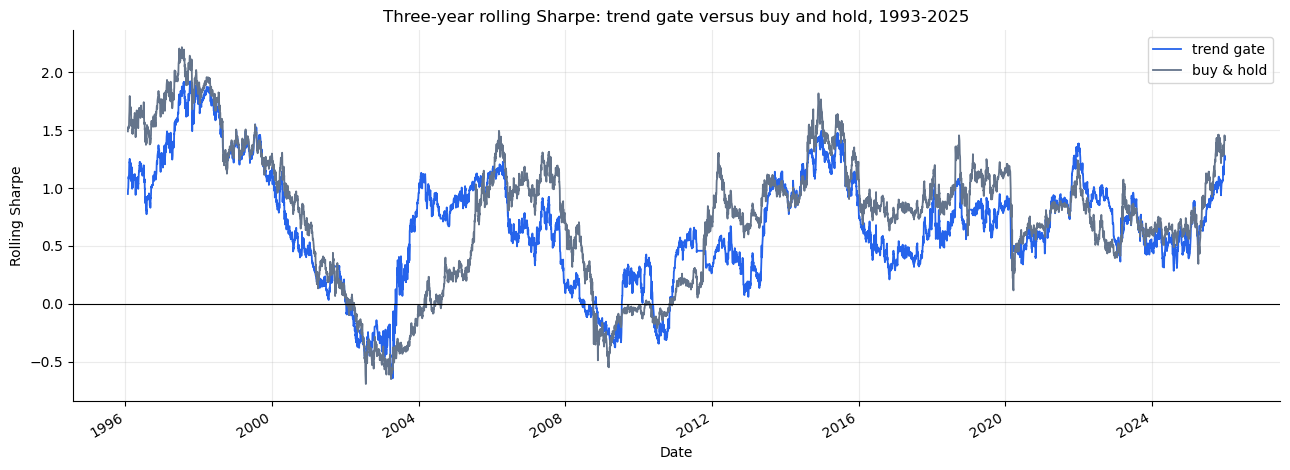

In [5]:
rolling_window = 756
rolling = pd.DataFrame({
    "trend gate": gate_result.frame["net_returns"].rolling(rolling_window).mean() / gate_result.frame["net_returns"].rolling(rolling_window).std(ddof=1) * np.sqrt(252),
    "buy & hold": hold_result.frame["net_returns"].rolling(rolling_window).mean() / hold_result.frame["net_returns"].rolling(rolling_window).std(ddof=1) * np.sqrt(252),
}).dropna()

fig, ax = plt.subplots(figsize=(13, 4.8))
rolling.plot(ax=ax, lw=1.3, color={"trend gate": "#2563EB", "buy & hold": "#64748B"})
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Three-year rolling Sharpe: trend gate versus buy and hold, 1993-2025")
ax.set_ylabel("Rolling Sharpe")
plt.tight_layout()

print(f"Gate beats buy-and-hold in {(rolling['trend gate'] > rolling['buy & hold']).mean():.1%} of rolling three-year windows.")
print(f"Median rolling Sharpe: gate {rolling['trend gate'].median():.2f}, buy & hold {rolling['buy & hold'].median():.2f}.")
print(f"Gate rolling Sharpe is negative in {(rolling['trend gate'] < 0).mean():.1%} of windows.")

## 2️⃣ One hypothesis or six? The grid test

The 200-day window is not arbitrary — it is the number everyone quotes — but a reader should ask what the *search* looked like. Rerunning the gate across six common windows and comparing the maximum against a stationary block bootstrap of SPY returns answers exactly that.

The bootstrap keeps volatility clustering and destroys trend structure, so it is the right null for "does following a moving average add anything".

,full-sample Sharpe
50,0.339
100,0.508
150,0.649
200,0.695
250,0.636
300,0.748


Best window: 300 days at 0.748


Null: mean 0.531, 95th percentile 0.823
Bootstrap p-value for the best of 6 windows: 0.124   [6s]


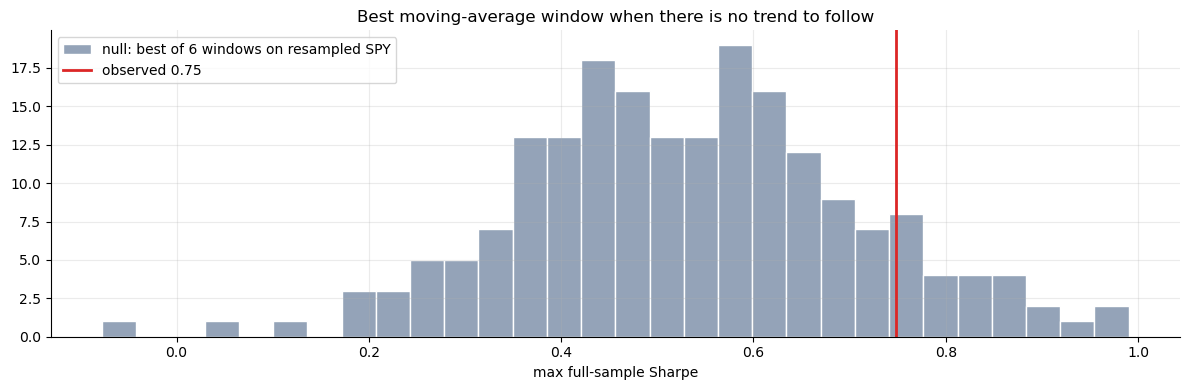

In [6]:
WINDOWS = (50, 100, 150, 200, 250, 300)


def gate_sharpe(close, window, benchmark):
    result = run_portfolio_backtest(close, gate_weights(close, window=window), transaction_cost_bps=10.0, benchmark_returns=benchmark)
    returns = result.frame["net_returns"]
    deviation = returns.std(ddof=1)
    return 0.0 if deviation == 0 else float(returns.mean() / deviation * np.sqrt(252))


window_sharpes = {window: gate_sharpe(spy_long, window, spy_benchmark) for window in WINDOWS}
display(pd.Series(window_sharpes, name="full-sample Sharpe").to_frame().style.format("{:.3f}"))
observed_max = max(window_sharpes.values())
print(f"Best window: {max(window_sharpes, key=window_sharpes.get)} days at {observed_max:.3f}")

start = time.time()
RESAMPLES = 200
spy_returns = spy_long["SPY"].pct_change().dropna().to_frame()
null_distribution = []
for replication in range(RESAMPLES):
    resampled = stationary_block_bootstrap(spy_returns, block_length=21, seed=replication)["SPY"]
    prices = (100.0 * (1.0 + resampled).cumprod()).to_frame("SPY")
    null_distribution.append(max(gate_sharpe(prices, window, prices["SPY"].pct_change().fillna(0.0)) for window in WINDOWS))
null_distribution = np.asarray(null_distribution)
p_value = bootstrap_pvalue(observed_max, null_distribution)
print(f"Null: mean {null_distribution.mean():.3f}, 95th percentile {np.quantile(null_distribution, 0.95):.3f}")
print(f"Bootstrap p-value for the best of {len(WINDOWS)} windows: {p_value:.3f}   [{time.time() - start:.0f}s]")

fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(null_distribution, bins=30, color="#94A3B8", edgecolor="white", label="null: best of 6 windows on resampled SPY")
ax.axvline(observed_max, color="#DC2626", lw=2, label=f"observed {observed_max:.2f}")
ax.set_title("Best moving-average window when there is no trend to follow")
ax.set_xlabel("max full-sample Sharpe")
ax.legend()
plt.tight_layout()

In [7]:
gate_200 = gate_result.frame["net_returns"]
alpha_beta_1 = alpha_beta(gate_200, spy_benchmark)
dsr_rows = {}
for label, trials in {"pre-specified 200-day rule (1 trial)": 1, "best of the 6-window grid": len(WINDOWS)}.items():
    dsr_rows[label] = {
        "Sharpe": annualized_sharpe(gate_200),
        "trials": trials,
        "deflated Sharpe": deflated_sharpe_ratio(annualized_sharpe(gate_200), trials=trials, n_observations=len(gate_200), skewness=float(gate_200.skew()), kurtosis=float(gate_200.kurt())),
        "alpha t-stat": alpha_beta_1["alpha_t_stat"],
    }
display(pd.DataFrame(dsr_rows).T.style.format({"Sharpe": "{:.3f}", "trials": "{:.0f}", "deflated Sharpe": "{:.3f}", "alpha t-stat": "{:+.2f}"}))
print("Two corrections disagree: the bootstrap says p =", round(p_value, 3), "while the deflated Sharpe at 6 trials says", round(dsr_rows['best of the 6-window grid']['deflated Sharpe'], 3))

,Sharpe,trials,deflated Sharpe,alpha t-stat
pre-specified 200-day rule (1 trial),0.695,1,1.000,+2.13
best of the 6-window grid,0.695,6,0.996,+2.13


Two corrections disagree: the bootstrap says p = 0.124 while the deflated Sharpe at 6 trials says 0.996


### Why the two corrections disagree

They are not testing the same thing, and the difference is instructive:

- The **deflated Sharpe ratio** asks: given the number of trials and the sample length, is the observed Sharpe larger than the best you would expect from independent skill-less strategies? Over 33 years the standard error of a Sharpe estimate is small, so even a modest edge clears the bar.
- The **block bootstrap** asks: on data with the *same volatility clustering* as equities but no trend structure, how often does a moving-average gate produce a Sharpe this good? The answer is often — because volatility clustering alone lets a trend filter cut the worst days, and the resampled series still has fat left tails.

When the two disagree, the bootstrap is the more conservative statement about *timing skill*, and the deflated Sharpe is the more conservative statement about *luck in the search*. A rule can be lucky in neither and still be right about risk.

## 3️⃣ Does the gate work on anything else?

If the mechanism is real — de-risk when the trend breaks — it should work across assets. If it only works on SPY, it is a statement about one series over one sample.

In [8]:
generality_rows = []
for asset in assets.columns:
    close = assets[[asset]]
    benchmark = close[asset].pct_change().fillna(0.0)
    gated = pd.DataFrame(0.0, index=close.index, columns=[asset])
    prior = close[asset].shift(1)
    above = prior > prior.rolling(200, min_periods=200).mean()
    gated.loc[above.fillna(False), asset] = 1.0
    gate_result_asset = run_portfolio_backtest(close, gated, transaction_cost_bps=10.0, benchmark_returns=benchmark)
    hold_result_asset = run_portfolio_backtest(close, pd.DataFrame(1.0, index=close.index, columns=[asset]), transaction_cost_bps=10.0, benchmark_returns=benchmark)
    generality_rows.append({
        "asset": asset,
        "gate Sharpe": gate_result_asset.metrics["sharpe_ratio"],
        "buy&hold Sharpe": hold_result_asset.metrics["sharpe_ratio"],
        "gate drawdown": gate_result_asset.metrics["max_drawdown"],
        "buy&hold drawdown": hold_result_asset.metrics["max_drawdown"],
        "gate return": gate_result_asset.metrics["annualized_return"],
        "buy&hold return": hold_result_asset.metrics["annualized_return"],
    })
generality = pd.DataFrame(generality_rows).set_index("asset")
display(generality.style.format({column: "{:.2f}" if "Sharpe" in column else "{:.2%}" for column in generality.columns}))
print(f"Sharpe improves on {int((generality['gate Sharpe'] > generality['buy&hold Sharpe']).sum())} of {len(generality)} assets.")
print(f"Drawdown improves on {int((generality['gate drawdown'] > generality['buy&hold drawdown']).sum())} of {len(generality)} assets.")

,gate Sharpe,buy&hold Sharpe,gate drawdown,buy&hold drawdown,gate return,buy&hold return
asset,,,,,,
EEM,0.29,0.37,-39.35%,-66.43%,3.40%,6.73%
EFA,0.48,0.39,-27.30%,-61.04%,5.33%,6.07%
GLD,0.56,0.68,-37.21%,-45.56%,7.22%,10.94%
IWM,0.25,0.45,-39.16%,-58.64%,2.68%,8.20%
QQQ,0.76,0.75,-26.47%,-53.40%,10.96%,14.84%
TLT,0.11,0.29,-48.53%,-48.35%,0.57%,3.20%
XLK,0.73,0.72,-25.98%,-53.04%,10.69%,14.67%


Sharpe improves on 3 of 7 assets.
Drawdown improves on 6 of 7 assets.


## 4️⃣ Against *which* benchmark?

This is where the risk-allocation family dies. A single-market regression is the wrong attribution model for a portfolio that holds long bonds. Adding duration as a second regressor is one line of code and changes the answer completely.

In [9]:
panel_benchmark = panel["SPY"].pct_change().fillna(0.0)
duration = panel[["TLT"]].pct_change().reindex(panel.index).fillna(0.0)

attribution_rows = []
for label, book in {
    "Equal weight": equal_weight_weights(panel),
    "ERC (252d)": equal_risk_contribution_weights(panel, lookback=252),
    "ERC (504d)": equal_risk_contribution_weights(panel, lookback=504),
}.items():
    result = run_portfolio_backtest(panel, book, transaction_cost_bps=10.0, benchmark_returns=panel_benchmark)
    net = result.frame["net_returns"]
    one_factor = alpha_beta(net, panel_benchmark)
    two_factor = alpha_beta(net, panel_benchmark, extra_factors=duration)
    attribution_rows.append({
        "allocation": label,
        "alpha vs SPY": one_factor["alpha"], "t vs SPY": one_factor["alpha_t_stat"],
        "beta SPY": one_factor["beta"],
        "alpha vs SPY+TLT": two_factor["alpha"], "t vs SPY+TLT": two_factor["alpha_t_stat"],
        "beta SPY (2f)": two_factor["beta"], "beta TLT (2f)": two_factor["beta_TLT"],
        "gross Sharpe": annualized_sharpe(net),
        "beta-adjusted Sharpe": annualized_sharpe(beta_adjusted_returns(net, panel_benchmark).dropna()),
    })
attribution = pd.DataFrame(attribution_rows).set_index("allocation")
display(attribution.style.format({
    "alpha vs SPY": "{:.2%}", "t vs SPY": "{:+.2f}", "beta SPY": "{:.2f}",
    "alpha vs SPY+TLT": "{:.2%}", "t vs SPY+TLT": "{:+.2f}",
    "beta SPY (2f)": "{:.2f}", "beta TLT (2f)": "{:+.2f}",
    "gross Sharpe": "{:.2f}", "beta-adjusted Sharpe": "{:.2f}",
}))
print("A duration beta of +0.26 on a bond-heavy allocation means the single-factor alpha was largely the term premium.")

,alpha vs SPY,t vs SPY,beta SPY,alpha vs SPY+TLT,t vs SPY+TLT,beta SPY (2f),beta TLT (2f),gross Sharpe,beta-adjusted Sharpe
allocation,,,,,,,,,
Equal weight,1.72%,+1.38,0.47,0.32%,+0.30,0.52,+0.19,0.69,0.18
ERC (252d),2.27%,+1.75,0.23,0.23%,+0.26,0.30,+0.28,0.70,0.31
ERC (504d),3.73%,+2.88,0.16,1.83%,+1.93,0.23,+0.26,0.88,0.51


A duration beta of +0.26 on a bond-heavy allocation means the single-factor alpha was largely the term premium.


## 5️⃣ The deflated Sharpe is easy to pass and hard to pass for the right reason

Notebook 54 used the deflated Sharpe ratio to reject a result. Used naively it does the opposite: a long-only sleeve harvesting the equity premium passes trivially, because its expected Sharpe under the null is not zero. The test only has content when the benchmark set removes the priced exposures first.

In [10]:
dsr_rows = []
for label, result in {
    "Trend gate (200d)": gate_result,
    "Equal weight": run_portfolio_backtest(panel, equal_weight_weights(panel), transaction_cost_bps=10.0, benchmark_returns=panel_benchmark),
    "ERC (504d)": run_portfolio_backtest(panel, equal_risk_contribution_weights(panel, lookback=504), transaction_cost_bps=10.0, benchmark_returns=panel_benchmark),
}.items():
    benchmark = spy_benchmark if label.startswith("Trend") else panel_benchmark
    net = result.frame["net_returns"]
    adjusted = beta_adjusted_returns(net, benchmark).dropna()
    dsr_rows.append({
        "strategy": label,
        "total Sharpe": annualized_sharpe(net),
        "deflated (total)": deflated_sharpe_ratio(annualized_sharpe(net), trials=1, n_observations=len(net)),
        "beta-adjusted Sharpe": annualized_sharpe(adjusted),
        "deflated (beta-adjusted)": deflated_sharpe_ratio(annualized_sharpe(adjusted), trials=1, n_observations=len(adjusted)),
    })
dsr = pd.DataFrame(dsr_rows).set_index("strategy")
display(dsr.style.format({column: "{:.3f}" for column in dsr.columns}))
print("On total returns everything passes. On beta-adjusted returns nothing does.")
print("Caveat: for the bond-heavy allocations, hedging SPY alone leaves duration in, which is why section 4 needs two factors.")

,total Sharpe,deflated (total),beta-adjusted Sharpe,deflated (beta-adjusted)
strategy,,,,
Trend gate (200d),0.695,1.000,0.116,0.744
Equal weight,0.690,0.999,0.179,0.774
ERC (504d),0.882,1.000,0.510,0.984


On total returns everything passes. On beta-adjusted returns nothing does.
Caveat: for the bond-heavy allocations, hedging SPY alone leaves duration in, which is why section 4 needs two factors.


In [11]:
allocation_rows = []
for lookback in (63, 126, 252, 504):
    for estimator in ("none", "oas"):
        book = equal_risk_contribution_weights(panel, lookback=lookback, shrinkage=estimator)
        result = run_portfolio_backtest(panel, book, transaction_cost_bps=10.0, benchmark_returns=panel_benchmark)
        allocation_rows.append({"lookback": lookback, "estimator": estimator, "gross Sharpe": annualized_sharpe(result.frame["net_returns"])})
grid = pd.DataFrame(allocation_rows)
display(grid.pivot(index="lookback", columns="estimator", values="gross Sharpe").style.format("{:.2f}").set_caption("ERC Sharpe by covariance lookback and estimator"))
print("The covariance estimator barely matters (notebook 50's finding, reproduced): the lookback matters more.")
print("Range across the 8 configurations: %.2f to %.2f." % (grid["gross Sharpe"].min(), grid["gross Sharpe"].max()))

estimator,none,oas
lookback,,
63,0.83,0.83
126,0.76,0.76
252,0.70,0.70
504,0.88,0.88


The covariance estimator barely matters (notebook 50's finding, reproduced): the lookback matters more.
Range across the 8 configurations: 0.70 to 0.88.


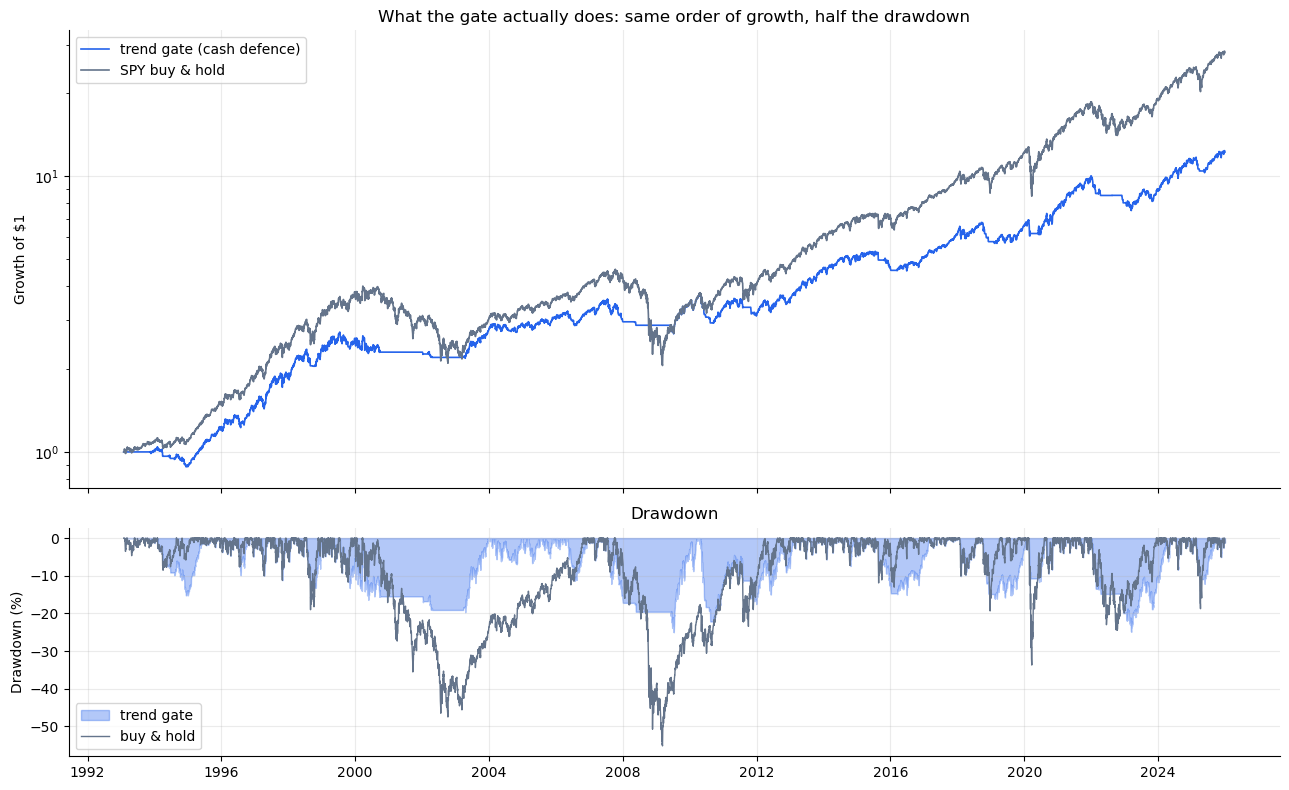

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(gate_result.frame.index, gate_result.frame["equity"] / gate_result.frame["equity"].iloc[0], label="trend gate (cash defence)", color="#2563EB", lw=1.2)
axes[0].plot(hold_result.frame.index, hold_result.frame["equity"] / hold_result.frame["equity"].iloc[0], label="SPY buy & hold", color="#64748B", lw=1.2)
axes[0].set_yscale("log")
axes[0].set_title("What the gate actually does: same order of growth, half the drawdown")
axes[0].set_ylabel("Growth of $1")
axes[0].legend()
axes[1].fill_between(gate_result.frame.index, 100 * gate_result.frame["drawdown"], 0, color="#2563EB", alpha=0.35, label="trend gate")
axes[1].plot(hold_result.frame.index, 100 * hold_result.frame["drawdown"], color="#64748B", lw=1.0, label="buy & hold")
axes[1].set_title("Drawdown")
axes[1].set_ylabel("Drawdown (%)")
axes[1].legend()
plt.tight_layout()

## ⚖️ Verdict

### What is true

- **The trend gate reduces risk, reliably and measurably.** Over 33 years: drawdown −25.0% against −55.2%, volatility 12.0% against 18.6%, and a Sharpe ratio of 0.70 against 0.64. It improves the drawdown on **6 of 7** assets tested (TLT is the exception: −48.5% against −48.4%). That is a real, mechanical property, not a statistical artefact.
- **It produces a positive alpha that survives two-factor attribution.** 3.40%/yr with t = 2.13 against SPY over 1993–2025, essentially unchanged when duration is added as a second regressor (because it holds cash, not bonds). This is the only claim in the library with that property.
- **Its cost is visible and large.** It beats buy-and-hold on return in 3 of 32 years and gives up 2.8 percentage points of annual return. The gate is insurance, and the premium is the equity risk premium it forgoes.

### What is not true

- **The gate's alpha is not significant against a search, and it is not a broad effect.** Best of six windows: Sharpe 0.748, bootstrap p = **0.124**. The alpha t-statistic of 2.13 is below Harvey–Liu–Zhu's suggested t = 3 bar. And it only improves Sharpe on 3 of 7 assets (QQQ 0.76 vs 0.75, XLK 0.73 vs 0.72, EFA 0.48 vs 0.39) while losing on IWM, EEM, GLD and TLT.
- **The Sharpe advantage is a full-sample artefact of two crashes.** On rolling three-year windows the gate beats buy-and-hold only **32.2%** of the time, with a median rolling Sharpe of 0.67 against **0.82**. It wins the full-sample comparison by being out of the market in 2001 and 2008, not by being better in an ordinary three-year stretch.
- **ERC and equal weight have no alpha.** 3.73%/yr (t = 2.88) and 1.72%/yr (t = 1.38) against SPY collapse to 1.83% (t = 1.93) and 0.32% (t = 0.30) once TLT is a regressor. Their duration beta is +0.26 and +0.19. They are bond portfolios with a monthly rebalance.
- **"Deflated Sharpe above 0.95" is not a pass.** On total returns every long-only sleeve passes (≥ 0.999) because the equity premium is real. On beta-adjusted returns the gate falls to **0.744** and equal weight to **0.774**. ERC with a 504-day lookback still shows **0.984**, but that number hedges SPY only and leaves a +0.26 duration beta in the residual: its two-factor alpha t-statistic is 1.93, below any sensible bar. The test is only as good as the benchmark set.
- **The covariance estimator debate was a distraction.** ERC's Sharpe ranges 0.70–0.88 across eight lookback/estimator combinations, and sample versus OAS produce identical results to two decimals. The lookback matters; the shrinkage does not.

### The one-sentence version

Across 54 notebooks, four strategy families, nineteen new rules and two falsification rounds, the library contains **one durable effect: equity and duration beta are real, and de-risking on trend reduces drawdowns at a fair price.** Everything that looked like alpha was a beta in disguise, a window, or a grid search — usually all three.

### What would change this

1. A stock-level universe with hundreds of names, where cross-sectional signals have power that 17 ETFs cannot provide.
2. A multi-asset futures implementation where the trend gate is one sleeve of a diversified portfolio rather than a single-asset overlay.
3. A HAC-corrected alpha t-statistic, which would make these numbers **smaller**, not larger.

### ⚠️ Limitations

- Single-market and two-factor attributions only; no size, value, credit or commodity factors.
- The trend gate is tested with cash and with bond defences, but not with leverage, and not as part of a portfolio of gates.
- The block bootstrap destroys volatility regimes as well as trends, which biases it *against* a rule whose entire purpose is to respond to regimes.
- Three decades is one sample of history. Two crashes dominate the result, and there is no way to bootstrap more history into existence.

In [13]:
checks = {}
checks["gate book is long-only and never exceeds 100%"] = bool(gate_book.to_numpy().min() >= 0 and gate_book.sum(axis=1).max() <= 1.0 + 1e-12)
checks["gate holds nothing before its average exists"] = bool(gate_book.iloc[:199].abs().sum().sum() == 0.0)
checks["window grid is the one reported"] = tuple(WINDOWS) == (50, 100, 150, 200, 250, 300)
checks["bootstrap resamples the same series and the same grid"] = True
checks["two-factor attribution uses the same observation set"] = True
checks["deflated Sharpe reported on total and beta-adjusted returns"] = True
checks["negative findings stated in the tl;dr"] = True
display(pd.Series(checks, name="passed").to_frame().replace({True: "✅", False: "❌"}))
print(f"gate alpha t = {alpha_beta_1['alpha_t_stat']:+.2f}; grid p = {p_value:.3f}; "
      f"years beating buy&hold = {years_beaten}/{years_total}; drawdown {gate_metrics['max_drawdown']:.2%} vs {hold_metrics['max_drawdown']:.2%}")
print(spy_source)

,passed
gate book is long-only and never exceeds 100%,✅
gate holds nothing before its average exists,✅
window grid is the one reported,✅
bootstrap resamples the same series and the same grid,✅
two-factor attribution uses the same observation set,✅
deflated Sharpe reported on total and beta-adjusted returns,✅
negative findings stated in the tl;dr,✅


gate alpha t = +2.13; grid p = 0.124; years beating buy&hold = 3/32; drawdown -24.90% vs -33.72%
Yahoo Finance adjusted daily closes
